# 01 · Exploración de los datos (Fase 1, hito 3)

Siniestros viales **con víctimas** en Cartagena (DATT, 2020–2025, CC-BY). Etiqueta: `fatal` = «Con muertos».

**Regla:** las tasas de fatalidad se calculan solo con **2020–2024** (entrenamiento + validación). La prueba (2025) no se usa para ninguna decisión; de ella solo se muestran conteos.

Todo lo numérico sale de `src/explore.py`, que también escribe `experiments/exploracion.json` y las figuras de `experiments/figuras/`. Este notebook solo lo ejecuta y lo muestra.

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
from src import config as C
from src.explore import resumen, figuras
pd.set_option('display.width', 140)
df = pd.read_csv(C.CLEAN_CSV, dtype={'localidad': str})
summary = json.loads((C.EXPERIMENTS / 'data_summary.json').read_text(encoding='utf-8'))
res = resumen(df, summary)
res['figuras'] = figuras(df, res, C.EXPERIMENTS / 'figuras')
(C.EXPERIMENTS / 'exploracion.json').write_text(json.dumps(res, indent=2, ensure_ascii=False), encoding='utf-8')
T = {k: pd.DataFrame(v) for k, v in res['tablas'].items()}
print('Filas limpias:', len(df), '| periodo de tasas:', res['periodo_tasas'])
print('n =', res['n_periodo_tasas'], '| fatales =', res['fatales_periodo_tasas'], '| tasa global =', res['tasa_global_periodo'])

Filas limpias: 7493 | periodo de tasas: 2020-2024 (entrenamiento + validación); 2025 excluido salvo conteos
n = 6103 | fatales = 454 | tasa global = 0.0744


## 1. Calidad: faltantes, fechas, horas y coordenadas

In [2]:
print('Fechas sin interpretar:', res['fecha_sin_interpretar'], '| horas sin interpretar:', res['hora_sin_interpretar'])
print('Coordenadas fuera de la caja de Cartagena o ausentes:', res['coordenadas_fuera_de_cartagena_o_ausentes'])
pd.Series(res['faltantes_pct_features'], name='% faltante o sin dato').sort_values(ascending=False).to_frame()

Fechas sin interpretar: 0 | horas sin interpretar: 0
Coordenadas fuera de la caja de Cartagena o ausentes: 26


,% faltante o sin dato
objeto_fijo,94.0
tipo_via,50.3
choque_con,24.9
lat,0.3
lon,0.3
dia_semana,0.0
hora,0.0
es_finde,0.0
es_noche,0.0
mes,0.0


La forma de registrar «sin dato» cambió entre años; por eso `preprocess.py` lo unifica (v3.1). Proporción de `sin_dato` por año y de `tipo_via` desconocido:

In [3]:
pd.DataFrame({**{f'{c}: sin_dato': v for c, v in res['sin_dato_por_anio'].items()},
              'tipo_via: desconocido': res['tipo_via_desconocido_por_anio']})

,choque_con: sin_dato,objeto_fijo: sin_dato,tipo_via: desconocido
2020,0.220,1.000,0.986
2021,0.208,1.000,0.986
2022,0.248,1.000,0.987
2023,0.273,0.945,0.054
2024,0.276,0.775,0.050
2025,0.263,0.931,0.064


## 2. Tasa de fatalidad por año
2025 aparece solo como conteo y prevalencia (ya publicadas en `data_summary.json`).

,anio,n,fatales,tasa,ic95_bajo,ic95_alto
0,2020,978,58,0.0593,0.0462,0.0759
1,2021,1317,77,0.0585,0.0470,0.0725
2,2022,1301,103,0.0792,0.0657,0.0951
3,2023,1254,103,0.0821,0.0682,0.0986
4,2024,1253,113,0.0902,0.0756,0.1073
5,2025,1390,115,0.0827,0.0694,0.0984


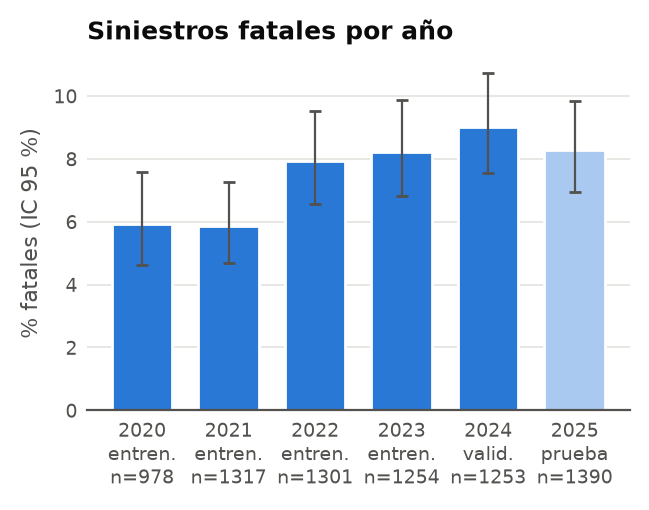

In [4]:
display(T['anio'])
display(Image(str(C.EXPERIMENTS / 'figuras' / 'fig1_tasa_por_anio.png'), width=420))

## 3. Franja horaria y hora del día

,franja,n,fatales,tasa,ic95_bajo,ic95_alto
0,madrugada,780,105,0.1346,0.1124,0.1604
1,manana,1813,96,0.0530,0.0436,0.0642
2,tarde,1888,109,0.0577,0.0481,0.0692
3,noche,1622,144,0.0888,0.0759,0.1036


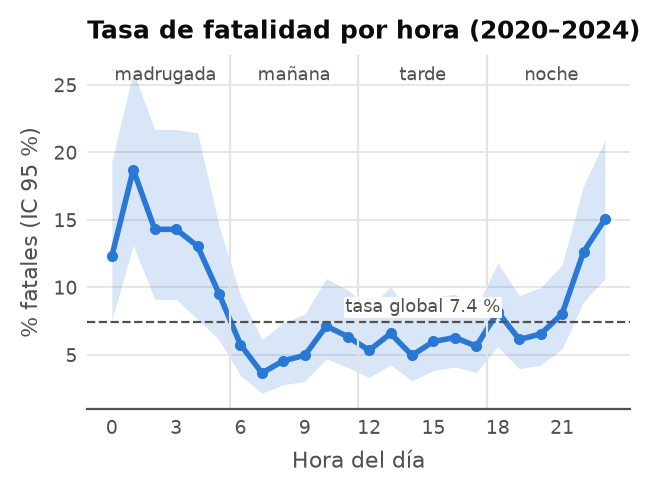

In [5]:
display(T['franja'])
display(Image(str(C.EXPERIMENTS / 'figuras' / 'fig2_tasa_por_hora.png'), width=420))

## 4. Clase de accidente, «choque con», objeto fijo y tipo de vía

clase_accidente


,clase_accidente,n,fatales,tasa,ic95_bajo,ic95_alto
0,choque,4604,266,0.0578,0.0514,0.0649
1,atropello,1240,148,0.1194,0.1025,0.1386
2,caida ocupante,142,23,0.1620,0.1104,0.2313
3,volcamiento,80,8,0.1000,0.0515,0.1851
4,otro,37,9,0.2432,0.1336,0.4012


choque_con


,choque_con,n,fatales,tasa,ic95_bajo,ic95_alto
0,vehiculo,4474,236,0.0527,0.0466,0.0597
1,sin_dato,1500,187,0.1247,0.1089,0.1423
2,objeto fijo,125,30,0.2400,0.1736,0.3219
3,semoviente,4,1,0.2500,0.0456,0.6994


objeto_fijo


,objeto_fijo,n,fatales,tasa,ic95_bajo,ic95_alto
0,sin_dato,5752,408,0.0709,0.0646,0.0779
1,objeto fijo,222,16,0.0721,0.0448,0.1139
2,muro,48,14,0.2917,0.1824,0.4318
3,otro,29,3,0.1034,0.0358,0.2639
4,vehiculo estacionado,25,7,0.2800,0.1428,0.4758
5,poste,11,3,0.2727,0.0975,0.5657
6,inmueble,7,0,0.0000,0.0000,0.3543
7,arbol,4,1,0.2500,0.0456,0.6994
8,hidrante,2,0,0.0000,0.0000,0.6576
9,baranda,1,1,1.0000,0.2065,1.0000


tipo_via


,tipo_via,n,fatales,tasa,ic95_bajo,ic95_alto
0,desconocido,3678,248,0.0674,0.0598,0.0760
1,calle,1333,91,0.0683,0.0559,0.0831
2,carrera,483,51,0.1056,0.0812,0.1362
3,diagonal,348,27,0.0776,0.0539,0.1105
4,transversal,144,7,0.0486,0.0237,0.0969
5,avenida,85,25,0.2941,0.2079,0.3982
6,corredor_carga,32,5,0.1562,0.0686,0.3175


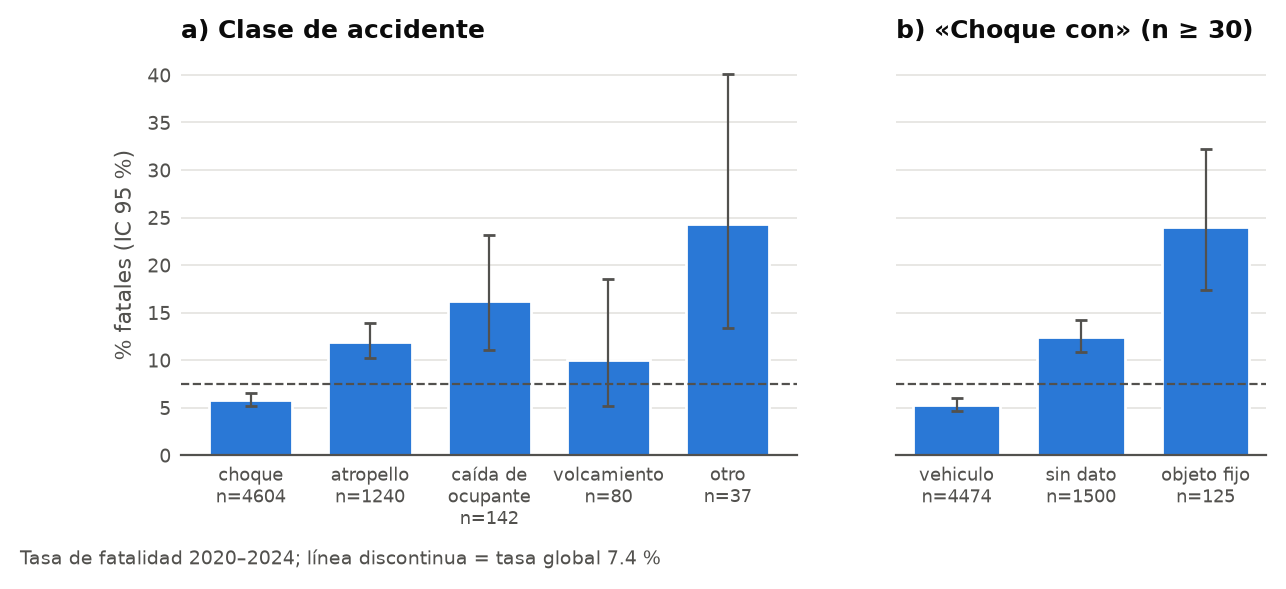

In [6]:
for k in ('clase_accidente', 'choque_con', 'objeto_fijo', 'tipo_via'):
    print(k); display(T[k])
display(Image(str(C.EXPERIMENTS / 'figuras' / 'fig3_tasa_por_clase_y_choque.png'), width=800))

## 5. Localidad y día de la semana

**Códigos de localidad.** El DATT no publica el diccionario del campo. Los barrios más frecuentes de cada código coinciden con la división oficial (1 = Histórica y del Caribe Norte, 2 = De la Virgen y Turística, 3 = Industrial y de la Bahía). Es una propuesta **[CONFIRMAR]** del equipo.

1 Histórica y del Caribe Norte -> ['bosque', 'bocagrande', 'centro', 'bazurto', 'manga', 'pie de la popa', 'marbella', 'san isidro']
2 De la Virgen y Turística -> ['olaya', 'el pozon', 'la esperanza', 'la maria', 'los alpes', 'alcibia', 'villa estrella', 'las palmeras']
3 Industrial y de la Bahía -> ['mamonal', 'ceballos', 'san fernando', 'san jose de los campanos', 'ternera', 'blas de lezo', 'el campestre', 'los caracoles']
Barrios con más de un código de localidad: 31


,localidad_nombre,n,fatales,tasa,ic95_bajo,ic95_alto
0,Histórica y del Caribe Norte,2757,185,0.0671,0.0584,0.0771
1,Industrial y de la Bahía,1876,144,0.0768,0.0656,0.0897
2,De la Virgen y Turística,1470,125,0.0850,0.0718,0.1004


,dia_nombre,n,fatales,tasa,ic95_bajo,ic95_alto
0,lunes,967,72,0.0745,0.0595,0.0927
1,martes,867,65,0.0750,0.0593,0.0944
2,miercoles,789,60,0.0760,0.0595,0.0967
3,jueves,790,61,0.0772,0.0606,0.0979
4,viernes,741,46,0.0621,0.0469,0.0818
5,sabado,910,58,0.0637,0.0496,0.0815
6,domingo,1039,92,0.0885,0.0728,0.1074


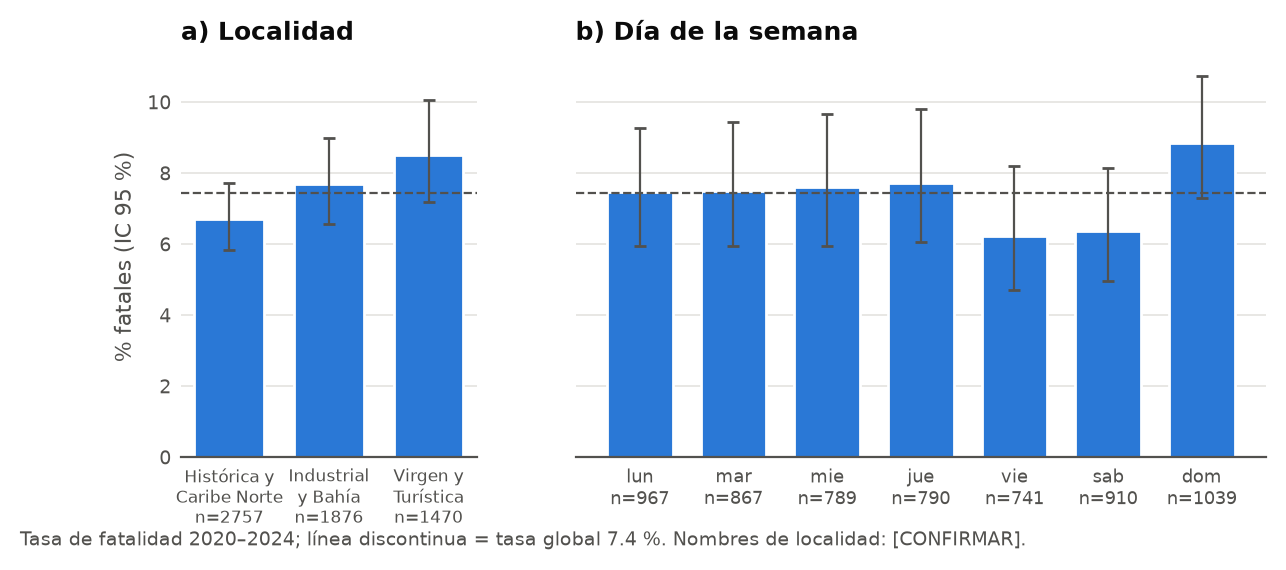

In [7]:
for k, v in res['localidad_codigos_barrios_top'].items():
    print(k, C.LOCALIDAD_NOMBRES.get(k), '->', list(v))
print('Barrios con más de un código de localidad:', res['localidad_barrios_con_mas_de_un_codigo'])
display(T['localidad']); display(T['dia_semana'])
display(Image(str(C.EXPERIMENTS / 'figuras' / 'fig4_tasa_por_localidad_y_dia.png'), width=800))

## 6. Cardinalidad (relevante para el modelado)

In [8]:
print(res['barrio'])
print('Códigos distintos en hipotesis_1:', res['hipotesis_1_n_codigos'])

{'n_categorias': 220, 'con_al_menos_20_casos': 81, 'pct_filas_en_barrios_con_20_o_mas': 0.871}
Códigos distintos en hipotesis_1: 88


## 7. Implicaciones para el modelado (Fase 2)

- **Señal horaria fuerte y no lineal:** la madrugada y las últimas horas de la noche tienen tasas muy por encima de la mañana. Esto favorece a modelos de árboles frente a un término lineal en `hora`.
- **Clase de accidente y «choque con»:** los atropellos, las caídas de ocupante y los choques contra objeto fijo superan la tasa global; los choques entre vehículos están por debajo. Son las variables del informe inicial con más señal.
- **Deriva temporal:** la prevalencia sube entre 2020–21 y 2024. Un modelo entrenado en 2020–23 tiende a subestimar la probabilidad en 2024–25, lo que afecta a la calibración y al umbral, pero no al ordenamiento (PR-AUC y ROC-AUC).
- **Datos parciales por año:** `tipo_via` y `objeto_fijo` casi no tienen información en 2020–22. Su aporte se mide en la ablación, no se supone.
- **`barrio`:** alta cardinalidad; con `min_frequency=20` solo los barrios frecuentes tienen categoría propia.
- **Localidad:** las diferencias entre localidades son pequeñas y sus IC 95 % se solapan.